In [2]:
from google.colab import files
uploaded = files.upload()

Saving EOG.csv to EOG.csv


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch, find_peaks

data = pd.read_csv('EOG.csv')  # your file

time = data.iloc[:,0].values
eog = data.iloc[:,1].values

fs = len(time) / (time[-1] - time[0])
print("Sampling Frequency:", fs)

Sampling Frequency: 10.892433862412423


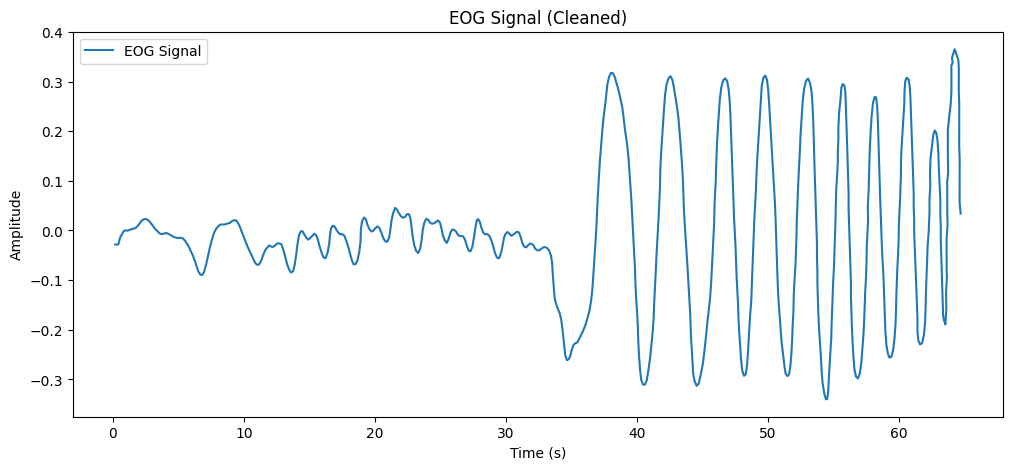

In [4]:
#Remove baseline
eog_detrended = eog - np.mean(eog)
#smooth signal
window = 5
eog_smooth = np.convolve(eog_detrended, np.ones(window)/window, mode='same')

plt.figure(figsize=(12,5))
plt.plot(time, eog_smooth, label="EOG Signal")
plt.title("EOG Signal (Cleaned)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.show()

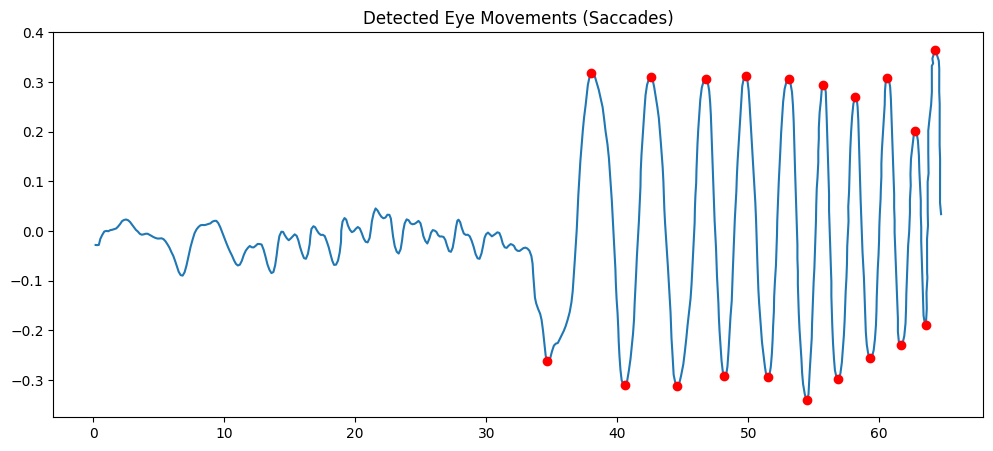

In [5]:
#Detect eye movements (saccades)
peaks, _ = find_peaks(np.abs(eog_smooth), height=np.std(eog_smooth))

plt.figure(figsize=(12,5))
plt.plot(time, eog_smooth)
plt.plot(time[peaks], eog_smooth[peaks], "ro")
plt.title("Detected Eye Movements (Saccades)")
plt.show()


In [6]:
#SNR for EOG (correct band: VERY LOW freq)
def compute_snr(signal, fs):
    f, Pxx = welch(signal, fs, nperseg=256)

    signal_power = np.sum(Pxx[(f >= 0.1) & (f <= 10)])
    noise_power = np.sum(Pxx) - signal_power

    return 10 * np.log10(signal_power / noise_power)

snr = compute_snr(eog_smooth, fs)
print("EOG SNR (dB):", snr)

EOG SNR (dB): 15.085120140615256


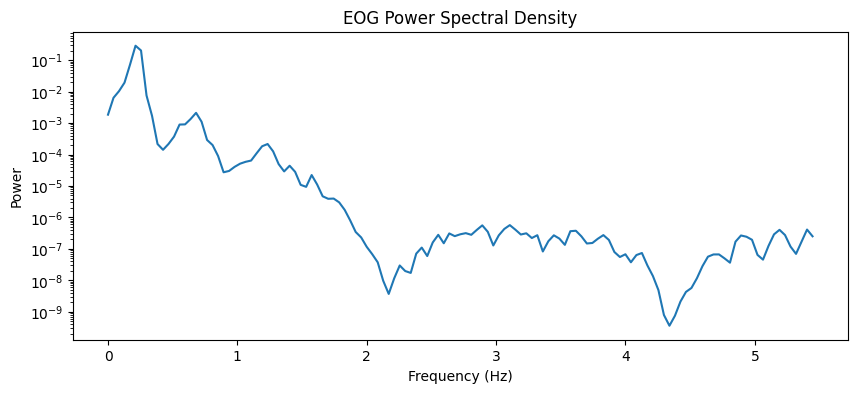

In [7]:
#PSD plot
f, Pxx = welch(eog_smooth, fs)

plt.figure(figsize=(10,4))
plt.semilogy(f, Pxx)
plt.title("EOG Power Spectral Density")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")
plt.show()